# 综合实验 1 文本分析 · 任务 10：商户维度可视化

- 10.1 好评率 Top10（极化样本 ≥30，Wilson 95% 下界排序，避免小样本/并列刷榜）；
- 10.2 Top10 周好评率折线（自然周聚合，周样本 <3 置空，4 周滚动）；
- 10.3 Top10 环境 / 口味 / 服务雷达图（子评分均值，已剔除 2.7 伪值）。

In [1]:
import sys
import numpy as np
import pandas as pd
from IPython.display import Image, display

SRC = "D:/DSH-Workspaces/数据科学/综合实验1/src"
sys.path.insert(0, SRC)
from config import TAB
import data_utils, viz_utils
from agg_utils import (top_by_wilson, bottom_by_ratio, weekly_counts,
                       rolling_ratio, restaurant_slice)

viz_utils.set_cn_font()
pd.set_option("display.width", 200)

agg = pd.read_csv(TAB / "rest_agg.csv")
print("商户聚合宽表:", agg.shape)

商户聚合宽表: (241360, 25)


In [2]:
top = top_by_wilson(agg, min_lab=30, k=10)
bottom = bottom_by_ratio(agg, min_lab=30, k=10)
name_map = dict(zip(top["restId"], top["name"]))

def disp(r, nm):
    return f"{r} {nm}" if isinstance(nm, str) and nm else f"{r}（无名称）"

top["display"] = [disp(r, nm) for r, nm in zip(top["restId"], top["name"])]
bottom["display"] = [disp(r, nm) for r, nm in zip(bottom["restId"], bottom["name"])]
print("=== 好评率最高 Top10（Wilson 下界排序）===")
display(top[["display", "n", "good", "bad", "lab", "ratio", "wilson",
             "env_mean", "flavor_mean", "service_mean"]].round(4))
print("=== 好评率最低 Top10（对照）===")
display(bottom[["display", "n", "good", "bad", "lab", "ratio", "wilson"]].round(4))

=== 好评率最高 Top10（Wilson 下界排序）===


,display,n,good,bad,lab,ratio,wilson,env_mean,flavor_mean,service_mean
234280,236034 海底捞火锅店(邯郸路店),203,194,0,194,1.0000,0.9806,3.5665,3.4236,4.4138
168342,169495 比萨马上诺(上海商城店),174,158,0,158,1.0000,0.9763,3.5977,3.6379,3.8046
79028,79493 王品台塑牛排(徐家汇店),171,150,0,150,1.0000,0.9750,3.8363,3.6959,4.2339
169698,170857 hoF Wine Bar & Brasserie,156,140,0,140,1.0000,0.9733,3.6282,3.7179,3.5769
139157,140085 都恩客(美罗城店),169,132,0,132,1.0000,0.9717,3.2781,3.4852,3.3195
186130,187529 莉莲蛋挞(长宁龙之梦店),140,127,0,127,1.0000,0.9706,2.7571,3.9000,2.7143
175035,176297 味藏铁板烧,139,122,0,122,1.0000,0.9695,3.3022,3.6619,3.4317
56195,56606 布歌东京(世纪联华店),145,120,0,120,1.0000,0.9690,3.1172,3.8828,3.4414
217248,218914 鱼屋新鲜馆,131,118,0,118,1.0000,0.9685,2.9237,3.6641,3.0382
142030,142993 檬舒舒(久光百货店),204,174,1,175,0.9943,0.9683,2.7647,3.6373,3.0931


=== 好评率最低 Top10（对照）===


,display,n,good,bad,lab,ratio,wilson
88233,88848 小任任风味小吃居,100,0,34,34,0.0000,0.0000
106565,107222 川惠自助火锅(田林路店),95,4,51,55,0.0727,0.0286
84184,84711 老上海弄堂菜,99,6,72,78,0.0769,0.0357
90436,91078 老叔冷面(来福士店),112,6,67,73,0.0822,0.0382
61736,62174 金泾避风塘,99,5,51,56,0.0893,0.0387
94698,95341 汉丽轩烤肉超市(方庄店),41,3,29,32,0.0938,0.0324
52105,52420 亚马逊巴西烧烤,99,6,56,62,0.0968,0.0451
164801,165945 老叔冷面(正大店),100,7,57,64,0.1094,0.0540
166236,167382 哈尼时尚小火锅,99,8,60,68,0.1176,0.0608
28463,28619 王四酒家,97,9,67,76,0.1184,0.0636


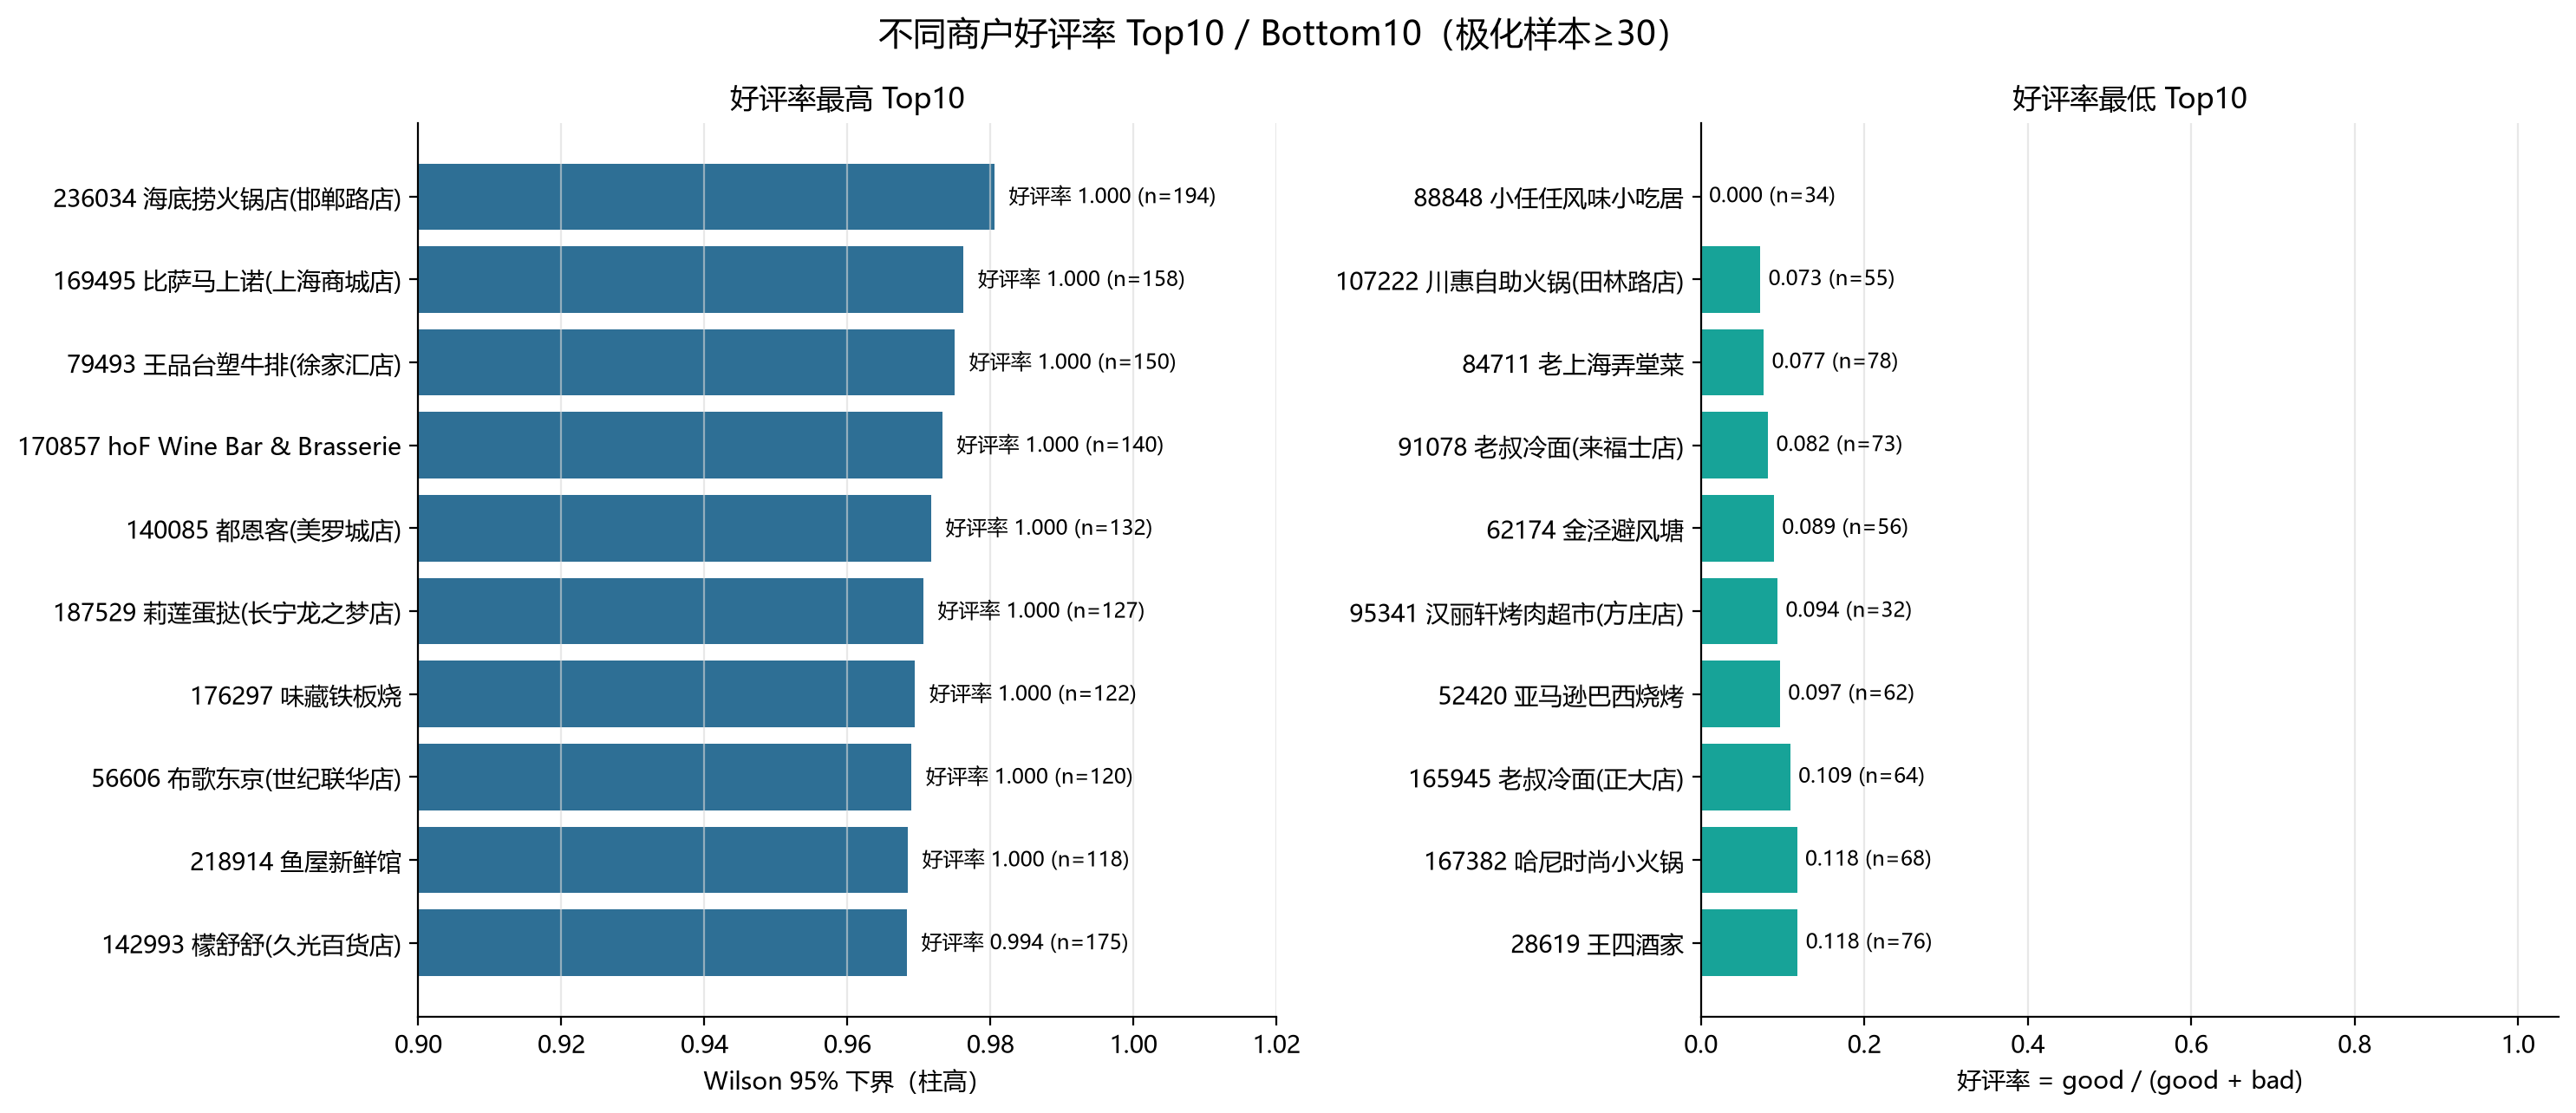

In [3]:
fig = viz_utils.plot_top_bottom_ratio(top, bottom, "fig10_1_top10_ratio.png",
                                     "不同商户好评率 Top10 / Bottom10（极化样本≥30）")
display(Image(filename=str(fig)))

top[["restId", "name", "n", "good", "bad", "lab", "ratio", "wilson"]].to_csv(
    TAB / "top10_ratio.csv", index=False, encoding="utf-8-sig")
bottom[["restId", "name", "n", "good", "bad", "lab", "ratio", "wilson"]].to_csv(
    TAB / "bottom10_ratio.csv", index=False, encoding="utf-8-sig")

In [4]:
# 10.2 周趋势：10.1 的 Top10 好评率均为 100%（周好评率恒为 1，曲线重合），无法体现变化；
# 因此改用「评论量 Top10」展示时间趋势（该口径已在报告中说明）。
top_n = agg.sort_values("n", ascending=False).head(10).copy()
top_n["display"] = [disp(r, nm) for r, nm in zip(top_n["restId"], top_n["name"])]
name_map_n = dict(zip(top_n["restId"], top_n["name"]))
display(top_n[["display", "n", "good", "bad", "lab", "ratio"]])

ids = top_n["restId"].tolist()
sub = restaurant_slice(ids, usecols=("restId", "rating", "timestamp"))
print("评论量 Top10 评论行数:", len(sub))
sub["label"] = data_utils.encode_label(sub["rating"], "A")
sub = sub[sub["label"].isin([0, 1])].copy()
sub["week"] = pd.to_datetime(sub["timestamp"], unit="ms").dt.to_period("W")
print("极化样本:", len(sub))

wk = weekly_counts(sub, ids)
wk_roll = rolling_ratio(wk, window=4, min_labels=3, roll_min=6)
print("周记录数:", len(wk), "| 有效滚动点:", int(wk_roll["ratio_roll"].notna().sum()))

,display,n,good,bad,lab,ratio
171884,173066 食之秘(长宁龙之梦店),226,159,12,171,0.929825
206319,207907 西九巷咖啡,225,151,9,160,0.943750
232307,234030 掌上韩品(吴江路店),214,123,11,134,0.917910
168646,169801 居食屋和民(来福士广场店),210,132,8,140,0.942857
22623,22690 花丸乌冬面,209,139,9,148,0.939189
200095,201535 红辣椒(张杨路店),209,181,4,185,0.978378
168455,169608 正斗粥面专家,209,130,8,138,0.942029
174339,175579 夏朵西餐厅,209,143,7,150,0.953333
196410,197839 辛香汇(大悦城店),208,166,9,175,0.948571
86801,87379 耶里夏丽新疆餐厅(东方店),208,164,5,169,0.970414


评论量 Top10 评论行数: 2127
极化样本: 1570
周记录数: 146 | 有效滚动点: 133


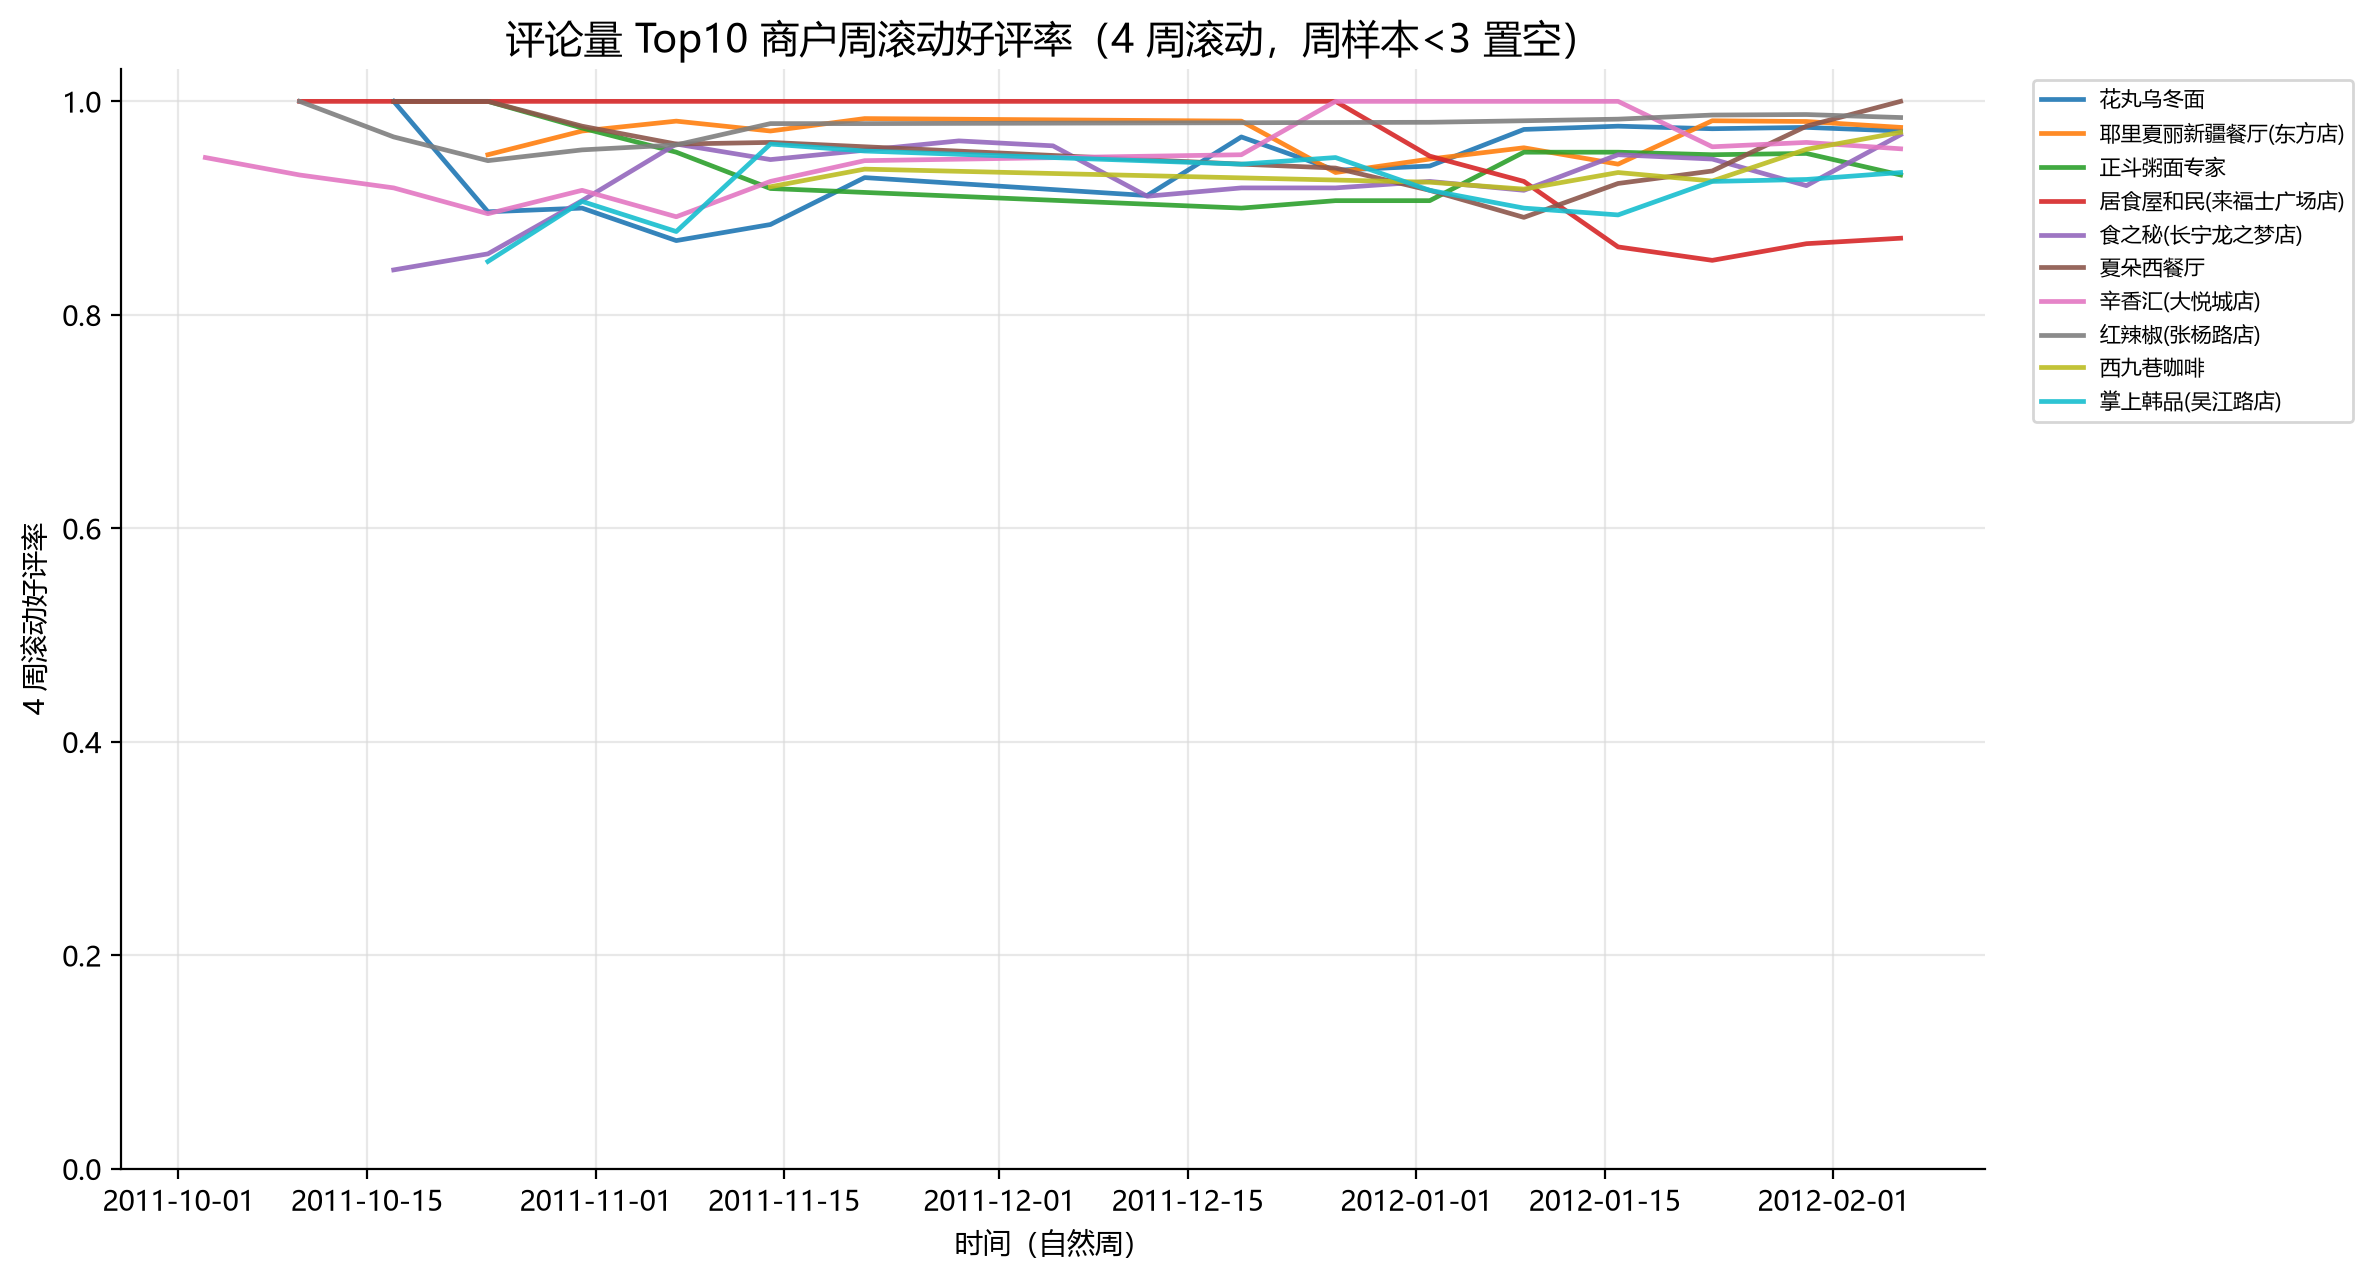

In [5]:
fig = viz_utils.plot_weekly_lines(wk_roll, name_map_n, "fig10_2_weekly_ratio_top10.png",
                                 "评论量 Top10 商户周滚动好评率（4 周滚动，周样本<3 置空）")
display(Image(filename=str(fig)))

In [6]:
# 10.3 雷达图
radar = top.set_index("restId")[["env_mean", "flavor_mean", "service_mean"]].copy()
labels = [disp(r, name_map.get(r)) for r in radar.index]
print(radar.round(3))

        env_mean  flavor_mean  service_mean
restId                                     
236034     3.567        3.424         4.414
169495     3.598        3.638         3.805
79493      3.836        3.696         4.234
170857     3.628        3.718         3.577
140085     3.278        3.485         3.320
187529     2.757        3.900         2.714
176297     3.302        3.662         3.432
56606      3.117        3.883         3.441
218914     2.924        3.664         3.038
142993     2.765        3.637         3.093


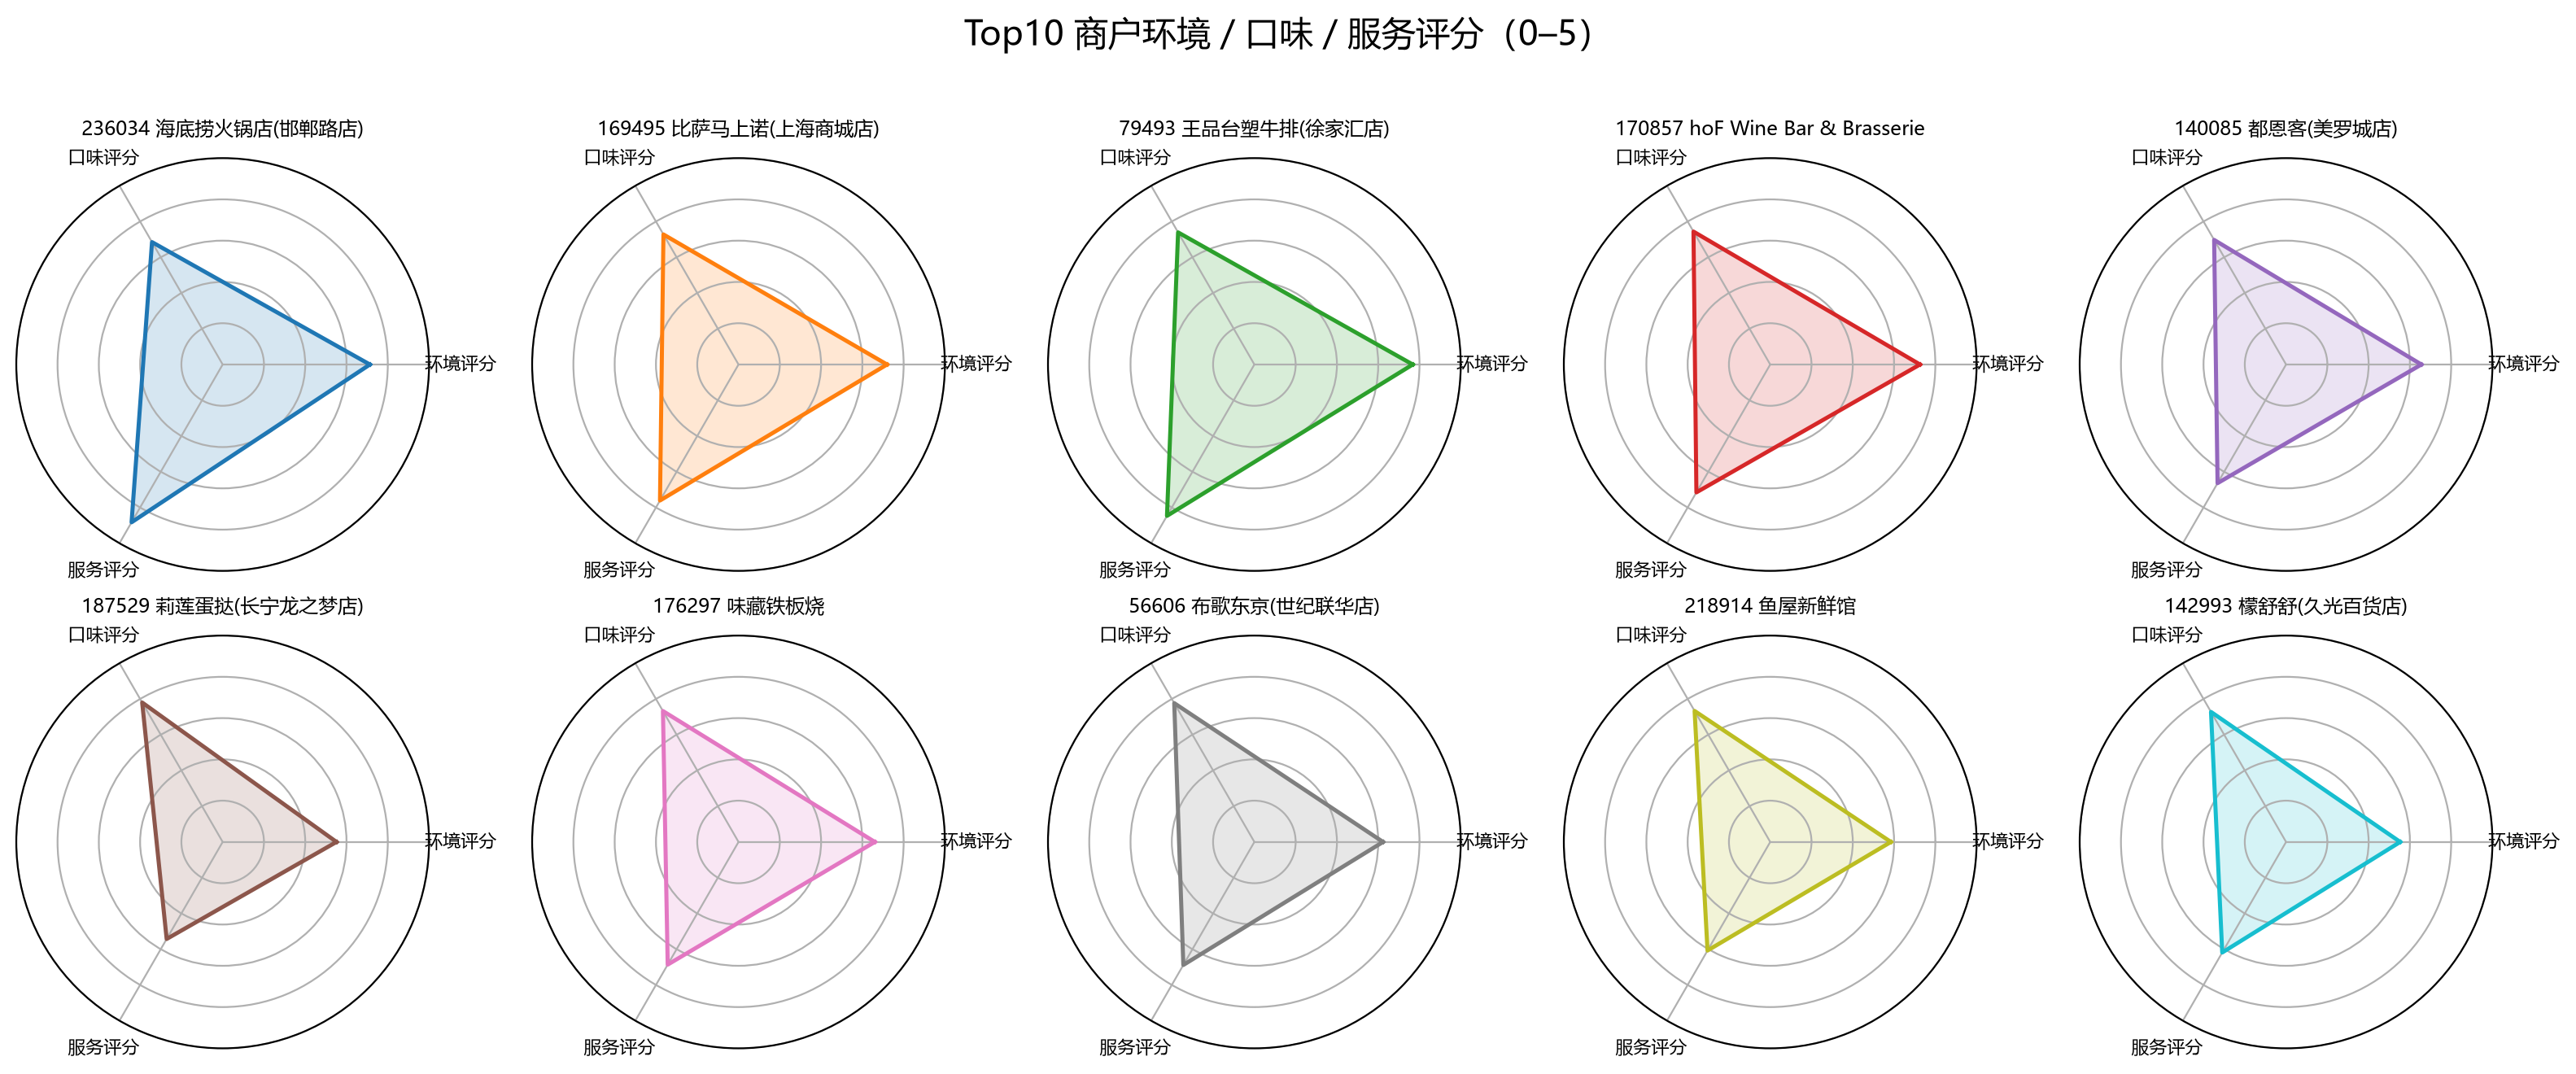

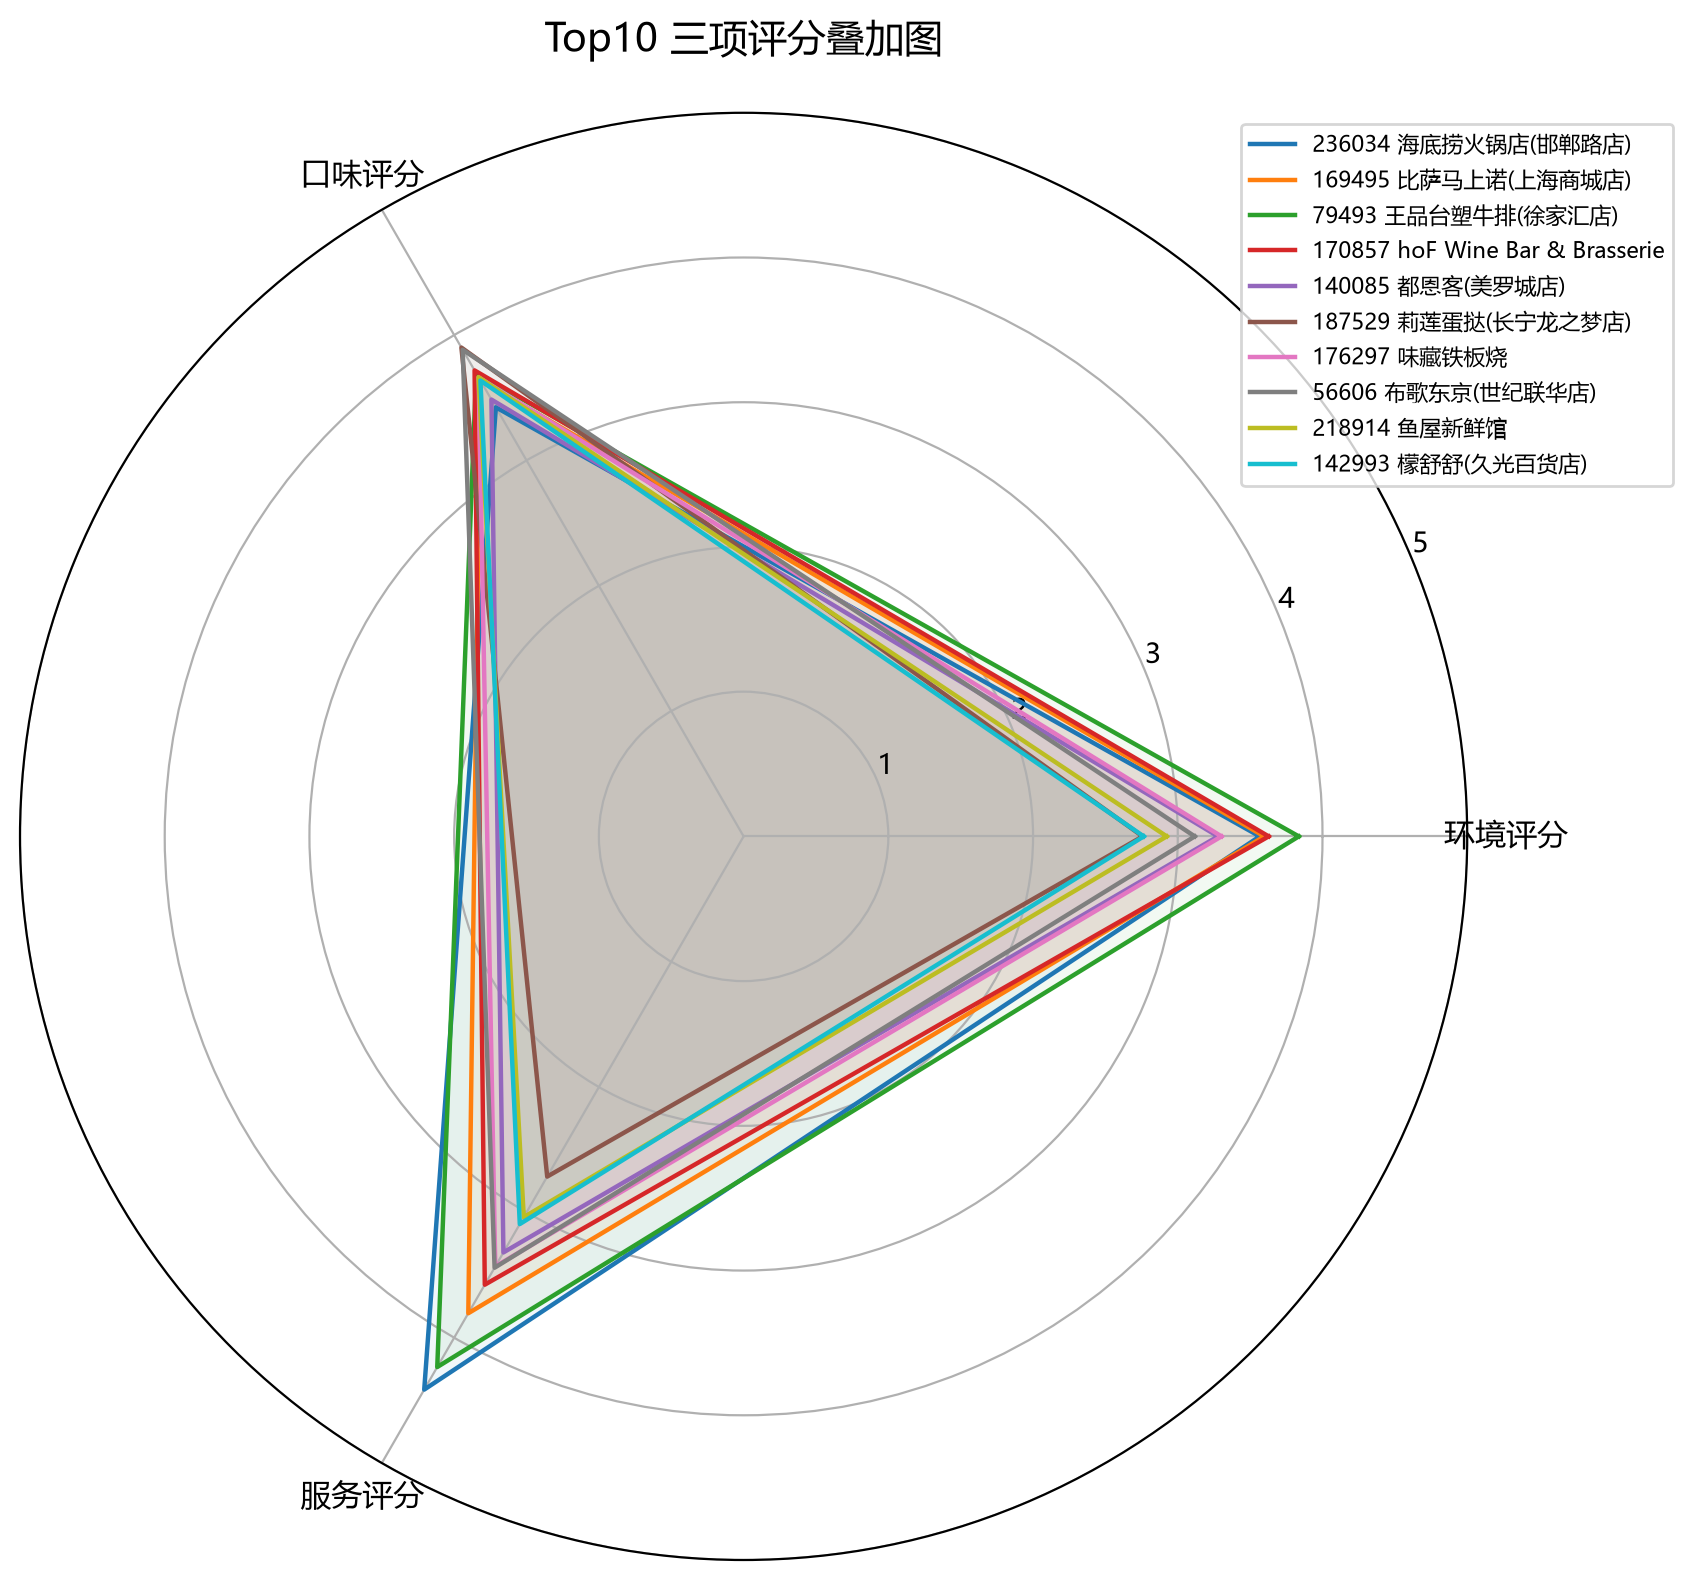

In [7]:
fig = viz_utils.plot_radar_grid(radar, "fig10_3_radar_grid.png",
                                "Top10 商户环境 / 口味 / 服务评分（0–5）", labels=labels, ncols=5)
display(Image(filename=str(fig)))

fig2 = viz_utils.plot_radar_multi(radar, "fig10_3_radar_overlay.png",
                                  "Top10 三项评分叠加图", labels=labels)
display(Image(filename=str(fig2)))

## 小结

- 好评率 Top10 由 Wilson 下界排序选出，样本量均在 130 条以上，避免「1 条好评 = 100%」的失真；
- 周趋势图显示 Top10 集中在 2011-08 ～ 2012-02（数据快照末端），周有效样本中位 4–10 条；
- 雷达图显示 Top10 三项评分整体偏高（口味 > 环境 ≈ 服务），与 88.62% 的全站好评率一致。